# Bases de datos · SQLAlchemy

El ORM de SQLAlchemy 2.x en estilo moderno (`DeclarativeBase`, `Mapped`, `mapped_column`, `select()` y `Session`) sobre la misma tienda del notebook anterior, guardada en `tienda_orm.db`.

## 1. Modelos

Definir los modelos `Cliente`, `Pedido`, `Linea`, `Producto` y `Etiqueta`:
- uno a muchos: un cliente tiene muchos pedidos y un pedido muchas líneas (con borrado en cascada),
- muchos a muchos con datos: `Linea` es el objeto de asociación entre pedidos y productos (cantidad y precio),
- muchos a muchos simple: productos y etiquetas a través de la tabla `producto_etiqueta`.

Crear las tablas, activar las claves foráneas de SQLite y mostrar el SQL que genera SQLAlchemy.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import Column, ForeignKey, String, Table, create_engine, delete, event, func, select, update
from sqlalchemy.exc import IntegrityError
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column, relationship, selectinload
from sqlalchemy.schema import CreateTable

Path("tienda_orm.db").unlink(missing_ok=True)
engine = create_engine("sqlite:///tienda_orm.db")

@event.listens_for(engine, "connect")
def activa_claves_foraneas(conexion_dbapi, _):
    cursor = conexion_dbapi.cursor()
    cursor.execute("PRAGMA foreign_keys = ON")
    cursor.close()

class Base(DeclarativeBase):
    pass

producto_etiqueta = Table(
    "producto_etiqueta",
    Base.metadata,
    Column("producto_id", ForeignKey("productos.id", ondelete="CASCADE"), primary_key=True),
    Column("etiqueta_id", ForeignKey("etiquetas.id", ondelete="CASCADE"), primary_key=True),
)

class Cliente(Base):
    __tablename__ = "clientes"
    id: Mapped[int] = mapped_column(primary_key=True)
    nombre: Mapped[str] = mapped_column(String(50))
    ciudad: Mapped[str] = mapped_column(String(30))
    pedidos: Mapped[list["Pedido"]] = relationship(back_populates="cliente", cascade="all, delete-orphan")

    def __repr__(self):
        return f"Cliente({self.nombre!r})"

class Pedido(Base):
    __tablename__ = "pedidos"
    id: Mapped[int] = mapped_column(primary_key=True)
    fecha: Mapped[date]
    cliente_id: Mapped[int] = mapped_column(ForeignKey("clientes.id"))
    cliente: Mapped[Cliente] = relationship(back_populates="pedidos")
    lineas: Mapped[list["Linea"]] = relationship(back_populates="pedido", cascade="all, delete-orphan")

    @property
    def total(self):
        return round(sum(l.cantidad * l.precio for l in self.lineas), 2)

    def __repr__(self):
        return f"Pedido({self.id}, {self.fecha})"

class Producto(Base):
    __tablename__ = "productos"
    id: Mapped[int] = mapped_column(primary_key=True)
    nombre: Mapped[str] = mapped_column(String(50), unique=True)
    categoria: Mapped[str] = mapped_column(String(30))
    precio: Mapped[float]
    etiquetas: Mapped[list["Etiqueta"]] = relationship(secondary=producto_etiqueta, back_populates="productos")

    def __repr__(self):
        return f"Producto({self.nombre!r})"

class Etiqueta(Base):
    __tablename__ = "etiquetas"
    id: Mapped[int] = mapped_column(primary_key=True)
    nombre: Mapped[str] = mapped_column(String(20), unique=True)
    productos: Mapped[list[Producto]] = relationship(secondary=producto_etiqueta, back_populates="etiquetas")

    def __repr__(self):
        return f"Etiqueta({self.nombre!r})"

class Linea(Base):
    __tablename__ = "lineas"
    pedido_id: Mapped[int] = mapped_column(ForeignKey("pedidos.id"), primary_key=True)
    producto_id: Mapped[int] = mapped_column(ForeignKey("productos.id"), primary_key=True)
    cantidad: Mapped[int]
    precio: Mapped[float]  # precio en el momento de la venta
    pedido: Mapped[Pedido] = relationship(back_populates="lineas")
    producto: Mapped[Producto] = relationship()

Base.metadata.create_all(engine)
print(list(Base.metadata.tables))
print(CreateTable(Linea.__table__).compile(engine))
print(CreateTable(producto_etiqueta).compile(engine))

['producto_etiqueta', 'clientes', 'pedidos', 'productos', 'etiquetas', 'lineas']

CREATE TABLE lineas (
	pedido_id INTEGER NOT NULL, 
	producto_id INTEGER NOT NULL, 
	cantidad INTEGER NOT NULL, 
	precio DOUBLE NOT NULL, 
	PRIMARY KEY (pedido_id, producto_id), 
	FOREIGN KEY(pedido_id) REFERENCES pedidos (id), 
	FOREIGN KEY(producto_id) REFERENCES productos (id)
)



CREATE TABLE producto_etiqueta (
	producto_id INTEGER NOT NULL, 
	etiqueta_id INTEGER NOT NULL, 
	PRIMARY KEY (producto_id, etiqueta_id), 
	FOREIGN KEY(producto_id) REFERENCES productos (id) ON DELETE CASCADE, 
	FOREIGN KEY(etiqueta_id) REFERENCES etiquetas (id) ON DELETE CASCADE
)




## 2. Crear objetos

Crear las etiquetas, los productos con sus etiquetas, los clientes y sus pedidos con líneas, y guardarlo todo con una sola llamada a `add_all` (la cascada añade los objetos relacionados). Comprobar que la base de datos asigna los `id` al confirmar.

In [2]:
etiquetas = {n: Etiqueta(nombre=n) for n in ["oferta", "novedad", "regalo"]}
datos_productos = [
    ("Teclado", "Informática", 35.0, ["oferta"]),
    ("Ratón", "Informática", 15.5, ["oferta", "regalo"]),
    ("Monitor", "Informática", 189.9, ["novedad"]),
    ("Cafetera", "Hogar", 79.0, ["regalo"]),
    ("Tostadora", "Hogar", 29.9, []),
    ("Novela", "Libros", 18.5, ["novedad", "regalo"]),
    ("Atlas", "Libros", 42.0, []),
    ("Lámpara", "Hogar", 24.0, ["oferta"]),
]
productos = {
    nombre: Producto(nombre=nombre, categoria=cat, precio=precio, etiquetas=[etiquetas[e] for e in ets])
    for nombre, cat, precio, ets in datos_productos
}
clientes = {
    nombre: Cliente(nombre=nombre, ciudad=ciudad)
    for nombre, ciudad in [("Ana Pérez", "Las Palmas"), ("Luis García", "Santa Cruz"), ("Carmen Díaz", "Las Palmas"),
                           ("Jorge Suárez", "La Laguna"), ("Elena Ramos", "Telde"), ("Pablo Hernández", "Arucas")]
}
pedidos = [
    ("Ana Pérez", date(2026, 1, 10), {"Teclado": 1, "Ratón": 2}),
    ("Luis García", date(2026, 1, 12), {"Monitor": 1}),
    ("Ana Pérez", date(2026, 2, 3), {"Novela": 3, "Atlas": 1}),
    ("Carmen Díaz", date(2026, 2, 14), {"Cafetera": 1, "Tostadora": 1}),
    ("Jorge Suárez", date(2026, 3, 1), {"Ratón": 1, "Novela": 2}),
    ("Luis García", date(2026, 3, 8), {"Teclado": 2, "Monitor": 1}),
    ("Elena Ramos", date(2026, 3, 20), {"Tostadora": 2}),
    ("Ana Pérez", date(2026, 4, 2), {"Cafetera": 1, "Ratón": 1}),
]
for cliente, fecha, articulos in pedidos:
    clientes[cliente].pedidos.append(Pedido(fecha=fecha, lineas=[
        Linea(producto=productos[p], cantidad=n, precio=productos[p].precio) for p, n in articulos.items()
    ]))

with Session(engine) as s:
    s.add_all(clientes.values())
    s.add(productos["Lámpara"])  # no está en ningún pedido: la cascada no llega a él
    print("Antes del commit:", productos["Teclado"].id)
    s.commit()
    print("Después del commit:", productos["Teclado"].id)
    for modelo in [Cliente, Pedido, Linea, Producto, Etiqueta]:
        print(modelo.__name__, s.scalar(select(func.count()).select_from(modelo)))
    assert s.scalar(select(func.count()).select_from(Linea)) == sum(len(a) for *_, a in pedidos)

Antes del commit: None
Después del commit: 1
Cliente 6
Pedido 8
Linea 14
Producto 8
Etiqueta 3


## 3. Leer

Recuperar un producto por clave primaria con `get`, los productos de informática del más caro al más barato, el número de pedidos, los clientes de Las Palmas y los productos entre 20 y 50 € (solo nombre y precio). Mostrar el SQL de una de las consultas.

In [3]:
with Session(engine) as s:
    print(s.get(Producto, 3))

    consulta = select(Producto).where(Producto.categoria == "Informática").order_by(Producto.precio.desc())
    print(consulta)
    informatica = s.scalars(consulta).all()
    print(informatica)

    print("Pedidos:", s.scalar(select(func.count(Pedido.id))))
    print(s.scalars(select(Cliente).where(Cliente.ciudad == "Las Palmas").order_by(Cliente.nombre)).all())
    filas = s.execute(select(Producto.nombre, Producto.precio).where(Producto.precio.between(20, 50))).all()
    print(filas, filas[0].nombre)

    assert [p.precio for p in informatica] == sorted((p.precio for p in informatica), reverse=True)
    assert {f.nombre for f in filas} == {n for n, _, precio, _ in datos_productos if 20 <= precio <= 50}

Producto('Cafetera')
SELECT productos.id, productos.nombre, productos.categoria, productos.precio 
FROM productos 
WHERE productos.categoria = :categoria_1 ORDER BY productos.precio DESC
[Producto('Monitor'), Producto('Teclado'), Producto('Ratón')]
Pedidos: 8
[Cliente('Ana Pérez'), Cliente('Carmen Díaz')]
[('Teclado', 35.0), ('Lámpara', 24.0), ('Atlas', 42.0), ('Tostadora', 29.9)] Teclado


## 4. Actualizar y borrar

Subir el precio de un producto modificando el objeto, rebajar un 10 % todos los libros con una sentencia `update()` y borrar un cliente nuevo con un pedido: la cascada debe borrar también el pedido y sus líneas. Borrar una etiqueta y comprobar que desaparecen sus filas de `producto_etiqueta`.

In [4]:
with Session(engine) as s:
    teclado = s.scalar(select(Producto).where(Producto.nombre == "Teclado"))
    teclado.precio = 37.5
    s.execute(update(Producto).where(Producto.categoria == "Libros").values(precio=func.round(Producto.precio * 0.9, 2)))
    s.commit()
    print(s.execute(select(Producto.nombre, Producto.precio).where(Producto.categoria != "Hogar")).all())

    temporal = Cliente(nombre="Temporal", ciudad="Gáldar")
    temporal.pedidos.append(Pedido(fecha=date(2026, 5, 1), lineas=[Linea(producto=teclado, cantidad=1, precio=37.5)]))
    s.add(temporal)
    s.commit()
    print("Pedidos con el temporal:", s.scalar(select(func.count(Pedido.id))))
    s.delete(temporal)
    s.commit()
    print("Pedidos tras borrarlo:", s.scalar(select(func.count(Pedido.id))))
    assert s.scalar(select(func.count(Pedido.id))) == len(pedidos)
    assert s.scalar(select(func.count()).select_from(Linea)) == sum(len(a) for *_, a in pedidos)

    asociaciones = lambda: s.scalar(select(func.count()).select_from(producto_etiqueta))
    antes = asociaciones()
    s.execute(delete(Etiqueta).where(Etiqueta.nombre == "regalo"))
    s.commit()
    print("Asociaciones:", antes, "->", asociaciones())
    assert antes - asociaciones() == 3

[('Teclado', 37.5), ('Ratón', 15.5), ('Novela', 16.65), ('Monitor', 189.9), ('Atlas', 37.8)]
Pedidos con el temporal: 9
Pedidos tras borrarlo: 8
Asociaciones: 8 -> 5


## 5. Transacciones

Intentar crear dos productos y, a continuación, uno con un nombre repetido dentro de `Session.begin()`: la restricción `UNIQUE` hace fallar el `commit` y la transacción entera se deshace.

In [5]:
def cuenta_productos():
    with Session(engine) as s:
        return s.scalar(select(func.count(Producto.id)))

antes = cuenta_productos()
try:
    with Session(engine) as s, s.begin():  # commit al salir, rollback si hay excepción
        s.add_all([Producto(nombre="Altavoz", categoria="Informática", precio=45.0),
                   Producto(nombre="Funda", categoria="Informática", precio=12.0),
                   Producto(nombre="Ratón", categoria="Informática", precio=9.9)])
except IntegrityError as e:
    print("Deshecha:", e.orig)
print("Productos:", antes, "->", cuenta_productos())
assert cuenta_productos() == antes

Deshecha: UNIQUE constraint failed: productos.nombre
Productos: 8 -> 8


## 6. Navegar por las relaciones

Mostrar los pedidos de Ana con sus líneas y su total, los productos con la etiqueta `oferta` y las etiquetas del ratón. Comprobar que `back_populates` mantiene los dos lados de la relación sincronizados antes de guardar.

In [6]:
with Session(engine) as s:
    ana = s.scalar(select(Cliente).where(Cliente.nombre == "Ana Pérez"))
    for pedido in ana.pedidos:
        print(pedido.fecha, [(l.producto.nombre, l.cantidad) for l in pedido.lineas], pedido.total)

    oferta = s.scalar(select(Etiqueta).where(Etiqueta.nombre == "oferta"))
    raton = s.scalar(select(Producto).where(Producto.nombre == "Ratón"))
    print(oferta.productos, raton.etiquetas, raton.etiquetas[0].productos)

    atlas = s.scalar(select(Producto).where(Producto.nombre == "Atlas"))
    atlas.etiquetas.append(oferta)
    print("Sin guardar:", atlas in oferta.productos)
    assert atlas in oferta.productos and ana.pedidos[0].cliente is ana
    s.rollback()

2026-01-10 [('Teclado', 1), ('Ratón', 2)] 66.0
2026-02-03 [('Novela', 3), ('Atlas', 1)] 97.5
2026-04-02 [('Ratón', 1), ('Cafetera', 1)] 94.5
[Producto('Teclado'), Producto('Ratón'), Producto('Lámpara')] [Etiqueta('oferta')] [Producto('Teclado'), Producto('Ratón'), Producto('Lámpara')]
Sin guardar: True


## 7. Consultas con `join`

Obtener los clientes que han comprado algún producto en oferta (`join` a través de pedidos, líneas, productos y etiquetas) y el número de pedidos de cada cliente incluyendo a los que no tienen ninguno (`outerjoin`). Comprobar el primer resultado navegando por los objetos.

In [7]:
with Session(engine) as s:
    consulta = (
        select(Cliente.nombre)
        .join(Cliente.pedidos).join(Pedido.lineas).join(Linea.producto).join(Producto.etiquetas)
        .where(Etiqueta.nombre == "oferta")
        .distinct().order_by(Cliente.nombre)
    )
    print(consulta, "\n")
    compradores = s.scalars(consulta).all()
    print(compradores)

    por_cliente = s.execute(
        select(Cliente.nombre, func.count(Pedido.id).label("pedidos"))
        .outerjoin(Cliente.pedidos).group_by(Cliente.id).order_by(Cliente.nombre)
    ).all()
    print(por_cliente)

    navegando = sorted({c.nombre for c in s.scalars(select(Cliente))
                        for p in c.pedidos for l in p.lineas
                        if any(e.nombre == "oferta" for e in l.producto.etiquetas)})
    assert compradores == navegando
    assert dict(por_cliente) == {c.nombre: len(c.pedidos) for c in s.scalars(select(Cliente))}

SELECT DISTINCT clientes.nombre 
FROM clientes JOIN pedidos ON clientes.id = pedidos.cliente_id JOIN lineas ON pedidos.id = lineas.pedido_id JOIN productos ON productos.id = lineas.producto_id JOIN producto_etiqueta AS producto_etiqueta_1 ON productos.id = producto_etiqueta_1.producto_id JOIN etiquetas ON etiquetas.id = producto_etiqueta_1.etiqueta_id 
WHERE etiquetas.nombre = :nombre_1 ORDER BY clientes.nombre 

['Ana Pérez', 'Jorge Suárez', 'Luis García']
[('Ana Pérez', 3), ('Carmen Díaz', 1), ('Elena Ramos', 1), ('Jorge Suárez', 1), ('Luis García', 2), ('Pablo Hernández', 0)]


## 8. Agregados

Calcular la facturación de cada cliente quedándose con los que superan 200 € (`group_by` y `having`), las unidades e ingresos por categoría y el producto más vendido.

In [8]:
importe = Linea.cantidad * Linea.precio
with Session(engine) as s:
    total = func.round(func.sum(importe), 2).label("total")
    grandes = s.execute(
        select(Cliente.nombre, total).join(Cliente.pedidos).join(Pedido.lineas)
        .group_by(Cliente.id).having(func.sum(importe) > 200).order_by(total.desc())
    ).all()
    print(grandes)

    for fila in s.execute(
        select(Producto.categoria, func.sum(Linea.cantidad).label("unidades"), func.round(func.sum(importe), 2))
        .join(Linea.producto).group_by(Producto.categoria).order_by(Producto.categoria)
    ):
        print(fila)

    unidades = func.sum(Linea.cantidad)
    print("Más vendido:", s.execute(
        select(Producto.nombre, unidades).join(Linea.producto).group_by(Producto.id).order_by(unidades.desc()).limit(1)
    ).one())

    gasto = {c.nombre: sum(p.total for p in c.pedidos) for c in s.scalars(select(Cliente))}
    assert {n for n, _ in grandes} == {n for n, g in gasto.items() if g > 200}

[('Luis García', 449.8), ('Ana Pérez', 258.0)]
('Hogar', 5, 247.7)
('Informática', 9, 546.8)
('Libros', 6, 134.5)
Más vendido: ('Novela', 5)


## 9. Carga perezosa frente a `selectinload`

Contar las sentencias SQL que se ejecutan al recorrer todos los clientes, sus pedidos y sus líneas. Con la carga perezosa por defecto aparece el problema N + 1 (una consulta por cada colección); con `selectinload` bastan tres consultas.

In [9]:
sentencias = []

@event.listens_for(engine, "before_cursor_execute")
def registra(conn, cursor, sql, parametros, contexto, executemany):
    sentencias.append(sql)

def recorre(consulta):
    sentencias.clear()
    with Session(engine) as s:
        resumen = {c.nombre: [(p.id, len(p.lineas)) for p in c.pedidos] for c in s.scalars(consulta)}
    return resumen, len(sentencias)

perezosa, n_perezosa = recorre(select(Cliente))
ansiosa, n_ansiosa = recorre(select(Cliente).options(selectinload(Cliente.pedidos).selectinload(Pedido.lineas)))
print("Perezosa:", n_perezosa, "consultas")
print("selectinload:", n_ansiosa, "consultas")
print(sentencias[-1])

n_clientes, n_pedidos = len(clientes), len(pedidos)
assert perezosa == ansiosa
assert n_perezosa == 1 + n_clientes + n_pedidos and n_ansiosa == 3
event.remove(engine, "before_cursor_execute", registra)

Perezosa: 15 consultas
selectinload: 3 consultas
SELECT lineas.pedido_id, lineas.producto_id, lineas.cantidad, lineas.precio 
FROM lineas 
WHERE lineas.pedido_id IN (?, ?, ?, ?, ?, ?, ?, ?)


## 10. `pandas.read_sql`

Cargar en un `DataFrame` todas las líneas de pedido con su fecha, cliente, producto, categoría e importe usando `pd.read_sql` con una consulta `select()` y el `engine`. Dibujar los ingresos por mes y categoría en barras apiladas y comprobar el total con el ORM.

,fecha,cliente,producto,categoria,cantidad,importe
0,2026-01-10,Ana Pérez,Teclado,Informática,1,35.0
1,2026-01-10,Ana Pérez,Ratón,Informática,2,31.0
2,2026-01-12,Luis García,Monitor,Informática,1,189.9
3,2026-02-03,Ana Pérez,Novela,Libros,3,55.5
4,2026-02-03,Ana Pérez,Atlas,Libros,1,42.0


categoria,Hogar,Informática,Libros
fecha,,,
2026-01,0.0,255.9,0.0
2026-02,108.9,0.0,97.5
2026-03,59.8,275.4,37.0
2026-04,79.0,15.5,0.0


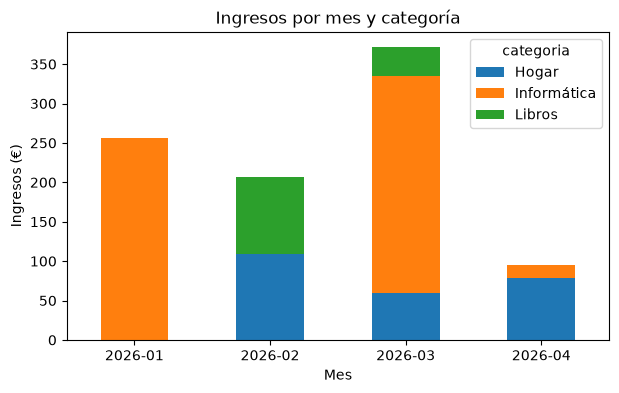

In [10]:
consulta = (
    select(Pedido.fecha, Cliente.nombre.label("cliente"), Producto.nombre.label("producto"),
           Producto.categoria, Linea.cantidad, importe.label("importe"))
    .join(Pedido.cliente).join(Pedido.lineas).join(Linea.producto)
    .order_by(Pedido.fecha)
)
df = pd.read_sql(consulta, engine, parse_dates=["fecha"])
display(df.head())

por_mes = df.pivot_table(index=df["fecha"].dt.strftime("%Y-%m"), columns="categoria", values="importe", aggfunc="sum", fill_value=0)
display(por_mes)
ax = por_mes.plot.bar(stacked=True, rot=0, figsize=(7, 4))
ax.set(xlabel="Mes", ylabel="Ingresos (€)", title="Ingresos por mes y categoría")
plt.show()

with Session(engine) as s:
    assert abs(df["importe"].sum() - s.scalar(select(func.sum(importe)))) < 1e-9
engine.dispose()